# Parcial 3 — Fila B
## Minería de Datos · Universidad del Norte
### Clustering jerárquico aglomerativo con enlace mínimo

Este cuaderno resuelve el parcial con el procedimiento del taller. Las celdas de texto son el desarrollo que se escribe en el examen. Las celdas de código reutilizan `d`, `d_clusters`, `merge` y `print_dist` para calcular las matrices y verificar el dendrograma.

Reglas del parcial:

- Distancia cuadrada: \(d^2(q_i,q_j)=(x_{1i}-x_{1j})^2+(x_{2i}-x_{2j})^2\).
- Enlace mínimo: la distancia entre dos clusters es la menor \(d^2\) entre un punto de cada uno.
- Si hay empate, se fusiona el par con los índices más pequeños.
- El orden de fusión coincide con el de la distancia euclidiana, porque \(d^2\) es creciente en \(d\).

Datos de la Fila B. \(x_1\) = horas de sesión diaria, \(x_2\) = géneros distintos por semana.

| Punto | \(x_1\) | \(x_2\) |
|------:|--------:|--------:|
| q1 | 0 | 2 |
| q2 | 2 | 3 |
| q3 | 3 | 0 |
| q4 | 6 | 1 |
| q5 | 8 | 5 |
| q6 | 7 | 7 |

In [1]:
%matplotlib inline

from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform

# Datos del parcial y de los dos ejercicios del taller.
FILA_B = [[0, 2], [2, 3], [3, 0], [6, 1], [8, 5], [7, 7]]
NOMBRES_B = ["q1", "q2", "q3", "q4", "q5", "q6"]

TALLER_1 = [[0, 0], [2, 0], [6, 1], [7, 3], [4, 5]]
NOMBRES_1 = ["r1", "r2", "r3", "r4", "r5"]

TALLER_2 = [[1, 1], [2, 3], [3, 1], [7, 5], [8, 4], [5, 7]]
NOMBRES_2 = ["s1", "s2", "s3", "s4", "s5", "s6"]

points = None
LABELS = None
clusters = None


def iniciar(data, names):
    """Deja la matriz de puntos y un cluster por cada punto."""
    global points, LABELS, clusters
    points = np.array(data, dtype=int)
    LABELS = list(names)
    clusters = {name: [i] for i, name in enumerate(LABELS)}


def d(i, j):
    """Distancia cuadrada entre los puntos i y j."""
    dx = int(points[i, 0]) - int(points[j, 0])
    dy = int(points[i, 1]) - int(points[j, 1])
    return dx * dx + dy * dy


def d_clusters(A, B):
    """Enlace mínimo: menor distancia entre un punto de A y uno de B."""
    return min(d(i, j) for i in A for j in B)


def merge(name_a, name_b, new_name):
    """Fusiona dos clusters en uno nuevo."""
    clusters[new_name] = clusters[name_a] + clusters[name_b]
    del clusters[name_a]
    del clusters[name_b]


def _nombres_ordenados():
    return sorted(clusters.keys(), key=lambda n: (min(clusters[n]), n))


def print_dist():
    """Imprime la matriz de distancias actual (triángulo superior)."""
    names = _nombres_ordenados()
    w = max(len(n) for n in names) + 2
    print(" " * w, end="")
    for n in names:
        print(f"{n:>{w}}", end="")
    print()
    for i, na in enumerate(names):
        print(f"{na:>{w}}", end="")
        for j, nb in enumerate(names):
            if j > i:
                valor = d_clusters(clusters[na], clusters[nb])
                print(f"{valor:>{w}d}", end="")
            elif j == i:
                print(f"{'—':>{w}}", end="")
            else:
                print(" " * w, end="")
        print()


def detalle_pares():
    """Escribe cada distancia cuadrada con la resta de coordenadas."""
    for i, j in combinations(range(len(LABELS)), 2):
        x1, y1 = int(points[i, 0]), int(points[i, 1])
        x2, y2 = int(points[j, 0]), int(points[j, 1])
        dx, dy = x1 - x2, y1 - y2
        print(
            f"d²({LABELS[i]}, {LABELS[j]}) = ({x1} - {x2})² + ({y1} - {y2})² "
            f"= {dx * dx} + {dy * dy} = {dx * dx + dy * dy}"
        )


def _clave_par(a, b):
    """Orden lexicográfico de los índices originales. El menor gana el empate."""
    ia = tuple(sorted(clusters[a]))
    ib = tuple(sorted(clusters[b]))
    if ia > ib:
        ia, ib = ib, ia
    return (ia, ib)


def siguiente_par():
    """Par de clusters con d² mínima. En empate, índices más pequeños."""
    names = list(clusters.keys())
    pares = []
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b = names[i], names[j]
            pares.append((d_clusters(clusters[a], clusters[b]), a, b))
    minimo = min(dist for dist, _, _ in pares)
    empatados = [(a, b) for dist, a, b in pares if dist == minimo]
    a, b = min(empatados, key=lambda par: _clave_par(*par))
    if min(clusters[a]) > min(clusters[b]):
        a, b = b, a
    return a, b, minimo, empatados


def actualizaciones(a, b):
    """d² del cluster nuevo hacia cada cluster que sigue vivo."""
    otros = [n for n in clusters if n not in (a, b)]
    otros.sort(key=lambda n: min(clusters[n]))
    for nombre in otros:
        da = d_clusters(clusters[a], clusters[nombre])
        db = d_clusters(clusters[b], clusters[nombre])
        print(f"  d²(nuevo, {nombre}) = min({da}, {db}) = {min(da, db)}")


def correr():
    """Ejecuta el algoritmo hasta un solo cluster e imprime cada matriz."""
    print("Matriz inicial")
    print_dist()
    historial = []
    for k in range(1, len(LABELS)):
        a, b, dist, empatados = siguiente_par()
        print(f"\n========== Paso {k} ==========")
        print(f"Mínimo d² = {dist}")
        if len(empatados) > 1:
            print("Hay empate entre:")
            for x, y in empatados:
                print(f"  - {x}  con  {y}")
            print("Criterio del parcial: se fusiona el par con índices más pequeños.")
        print(f"Se fusionan {a} y {b} a altura d² = {dist}.")
        actualizaciones(a, b)
        miembros = sorted(clusters[a] + clusters[b])
        nuevo = "{" + ", ".join(LABELS[i] for i in miembros) + "}"
        merge(a, b, nuevo)
        print("Matriz actualizada:")
        print_dist()
        historial.append((nuevo, dist))
    return historial


def matriz_d2():
    n = len(points)
    D = np.zeros((n, n))
    for i, j in combinations(range(n), 2):
        D[i, j] = D[j, i] = d(i, j)
    return D


def linkage_d2():
    return linkage(squareform(matriz_d2()), method="single")


def dendrograma(titulo, corte=None, color_corte=None):
    Z = linkage_d2()
    fig, ax = plt.subplots(figsize=(8.2, 4.6))
    umbral = color_corte if color_corte is not None else 0.7 * Z[:, 2].max()
    dendrogram(Z, labels=list(LABELS), ax=ax, color_threshold=umbral)
    alturas = sorted(set(float(h) for h in Z[:, 2]))
    ax.set_yticks([0, *alturas])
    ax.set_ylabel("d²")
    ax.set_title(titulo)
    if corte is not None:
        ax.axhline(corte, color="0.35", ls="--", lw=1, label=f"corte en d² = {corte:g}")
        ax.legend(loc="upper right")
    ax.set_ylim(bottom=-0.8)
    fig.tight_layout()
    plt.show()
    return Z


def dispersion(titulo):
    fig, ax = plt.subplots(figsize=(6.2, 5.6))
    ax.scatter(points[:, 0], points[:, 1], s=90, c="#1f4e79", zorder=3)
    for i, name in enumerate(LABELS):
        ax.annotate(name, points[i], textcoords="offset points", xytext=(7, 6), fontsize=11)
    ax.set_xlabel("x1   horas de sesión diaria")
    ax.set_ylabel("x2   géneros por semana")
    ax.set_title(titulo)
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(True, ls=":", alpha=0.7)
    fig.tight_layout()
    plt.show()


def figura_encadenamiento():
    """Muestra por qué q3 y q4 siguen la cadena hacia q1 y q2."""
    fig, ax = plt.subplots(figsize=(7.2, 5.8))
    izquierda = [0, 1, 2, 3]
    derecha = [4, 5]
    ax.scatter(
        points[izquierda, 0], points[izquierda, 1],
        s=100, c="#1f4e79", label="{q1, q2, q3, q4}", zorder=3,
    )
    ax.scatter(
        points[derecha, 0], points[derecha, 1],
        s=100, c="#c45911", label="{q5, q6}", zorder=3,
    )
    for i, name in enumerate(LABELS):
        ax.annotate(name, points[i], textcoords="offset points", xytext=(7, 6), fontsize=11)
    for i, j in ((1, 2), (2, 3), (3, 4)):
        color = "#1f4e79" if j != 4 else "#c45911"
        ax.plot(
            [points[i, 0], points[j, 0]],
            [points[i, 1], points[j, 1]],
            color=color, lw=1.6, zorder=2,
        )
        medio = (points[i] + points[j]) / 2
        valor = d(i, j)
        ax.annotate(
            f"d² = {valor}",
            medio,
            textcoords="offset points",
            xytext=(6, -14),
            color=color,
            fontsize=10,
        )
    ax.set_xlabel("x1   horas de sesión diaria")
    ax.set_ylabel("x2   géneros por semana")
    ax.set_title("Enlace mínimo: q4 queda a d² = 10 de q3 y a d² = 20 de q5")
    ax.legend(loc="upper left")
    ax.grid(True, ls=":", alpha=0.7)
    fig.tight_layout()
    plt.show()


def clusters_al_corte(t):
    grupos = fcluster(linkage_d2(), t=t, criterion="distance")
    partidos = {}
    for nombre, grupo in zip(LABELS, grupos):
        partidos.setdefault(int(grupo), []).append(nombre)
    return list(partidos.values())

## Pregunta 1 (25 pts) — Matriz de distancias cuadradas

Hay \(\binom{6}{2}=15\) pares. Para cada par se calcula \((\Delta x_1)^2+(\Delta x_2)^2\).

1. \(d^2(q_1,q_2)=(0-2)^2+(2-3)^2=4+1=5\)
2. \(d^2(q_1,q_3)=(0-3)^2+(2-0)^2=9+4=13\)
3. \(d^2(q_1,q_4)=(0-6)^2+(2-1)^2=36+1=37\)
4. \(d^2(q_1,q_5)=(0-8)^2+(2-5)^2=64+9=73\)
5. \(d^2(q_1,q_6)=(0-7)^2+(2-7)^2=49+25=74\)
6. \(d^2(q_2,q_3)=(2-3)^2+(3-0)^2=1+9=10\)
7. \(d^2(q_2,q_4)=(2-6)^2+(3-1)^2=16+4=20\)
8. \(d^2(q_2,q_5)=(2-8)^2+(3-5)^2=36+4=40\)
9. \(d^2(q_2,q_6)=(2-7)^2+(3-7)^2=25+16=41\)
10. \(d^2(q_3,q_4)=(3-6)^2+(0-1)^2=9+1=10\)
11. \(d^2(q_3,q_5)=(3-8)^2+(0-5)^2=25+25=50\)
12. \(d^2(q_3,q_6)=(3-7)^2+(0-7)^2=16+49=65\)
13. \(d^2(q_4,q_5)=(6-8)^2+(1-5)^2=4+16=20\)
14. \(d^2(q_4,q_6)=(6-7)^2+(1-7)^2=1+36=37\)
15. \(d^2(q_5,q_6)=(8-7)^2+(5-7)^2=1+4=5\)

Triángulo superior:

| | q1 | q2 | q3 | q4 | q5 | q6 |
|---|---:|---:|---:|---:|---:|---:|
| q1 | — | 5 | 13 | 37 | 73 | 74 |
| q2 | | — | 10 | 20 | 40 | 41 |
| q3 | | | — | 10 | 50 | 65 |
| q4 | | | | — | 20 | 37 |
| q5 | | | | | — | 5 |
| q6 | | | | | | — |

El mínimo de la matriz es \(d^2=5\), y aparece dos veces: en \(\{q_1,q_2\}\) y en \(\{q_5,q_6\}\).

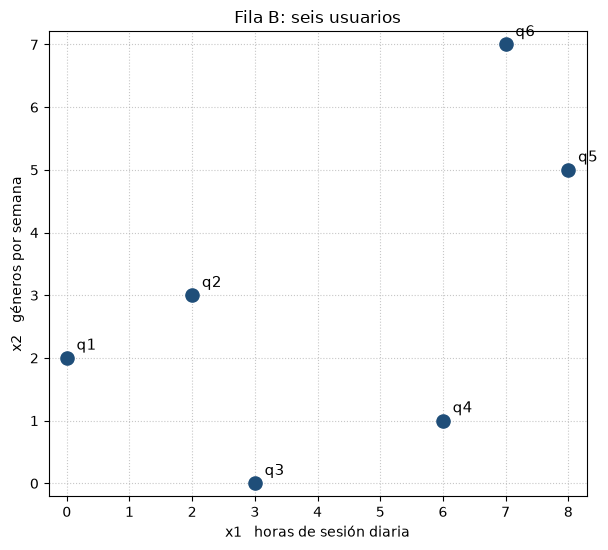

d²(q1, q2) = (0 - 2)² + (2 - 3)² = 4 + 1 = 5
d²(q1, q3) = (0 - 3)² + (2 - 0)² = 9 + 4 = 13
d²(q1, q4) = (0 - 6)² + (2 - 1)² = 36 + 1 = 37
d²(q1, q5) = (0 - 8)² + (2 - 5)² = 64 + 9 = 73
d²(q1, q6) = (0 - 7)² + (2 - 7)² = 49 + 25 = 74
d²(q2, q3) = (2 - 3)² + (3 - 0)² = 1 + 9 = 10
d²(q2, q4) = (2 - 6)² + (3 - 1)² = 16 + 4 = 20
d²(q2, q5) = (2 - 8)² + (3 - 5)² = 36 + 4 = 40
d²(q2, q6) = (2 - 7)² + (3 - 7)² = 25 + 16 = 41
d²(q3, q4) = (3 - 6)² + (0 - 1)² = 9 + 1 = 10
d²(q3, q5) = (3 - 8)² + (0 - 5)² = 25 + 25 = 50
d²(q3, q6) = (3 - 7)² + (0 - 7)² = 16 + 49 = 65
d²(q4, q5) = (6 - 8)² + (1 - 5)² = 4 + 16 = 20
d²(q4, q6) = (6 - 7)² + (1 - 7)² = 1 + 36 = 37
d²(q5, q6) = (8 - 7)² + (5 - 7)² = 1 + 4 = 5

      q1  q2  q3  q4  q5  q6
  q1   —   5  13  37  73  74
  q2       —  10  20  40  41
  q3           —  10  50  65
  q4               —  20  37
  q5                   —   5
  q6                       —


In [2]:
iniciar(FILA_B, NOMBRES_B)
dispersion("Fila B: seis usuarios")
detalle_pares()
print()
print_dist()

## Pregunta 2 (45 pts) — Algoritmo aglomerativo con enlace mínimo

En cada paso se fusionan los dos clusters de menor \(d^2\). La distancia del cluster nuevo hacia cualquier otro cluster \(X\) es el mínimo de las distancias de sus dos componentes:

\[
d^2(A\cup B,\, X)=\min\bigl(d^2(A,X),\, d^2(B,X)\bigr).
\]

Si dos pares tienen la misma \(d^2\), se elige el par cuyos índices originales son más pequeños. \(\{q_1,q_2\}\) (índices 1 y 2) gana a \(\{q_5,q_6\}\) (índices 5 y 6). Un cluster ya fusionado se representa por los índices de los puntos que contiene: gana el par que, al ordenar esos índices, queda primero en orden lexicográfico.

### Paso 1

Mínimo \(d^2=5\). Empate entre \(\{q_1,q_2\}\) y \(\{q_5,q_6\}\). Se fusionan **q1 y q2**.

\[
\begin{align*}
d^2(\{q_1,q_2\}, q_3)&=\min(13,10)=10\\
d^2(\{q_1,q_2\}, q_4)&=\min(37,20)=20\\
d^2(\{q_1,q_2\}, q_5)&=\min(73,40)=40\\
d^2(\{q_1,q_2\}, q_6)&=\min(74,41)=41
\end{align*}
\]

| | {q1, q2} | q3 | q4 | q5 | q6 |
|---|---:|---:|---:|---:|---:|
| {q1, q2} | — | 10 | 20 | 40 | 41 |
| q3 | | — | 10 | 50 | 65 |
| q4 | | | — | 20 | 37 |
| q5 | | | | — | 5 |
| q6 | | | | | — |

### Paso 2

Mínimo \(d^2=5\), ahora único: **q5 y q6**.

\[
\begin{align*}
d^2(\{q_5,q_6\}, \{q_1,q_2\})&=\min(40,41)=40\\
d^2(\{q_5,q_6\}, q_3)&=\min(50,65)=50\\
d^2(\{q_5,q_6\}, q_4)&=\min(20,37)=20
\end{align*}
\]

| | {q1, q2} | q3 | q4 | {q5, q6} |
|---|---:|---:|---:|---:|
| {q1, q2} | — | 10 | 20 | 40 |
| q3 | | — | 10 | 50 |
| q4 | | | — | 20 |
| {q5, q6} | | | | — |

### Paso 3

Mínimo \(d^2=10\). Empate entre \(\{q_1,q_2\}\) con \(q_3\), y \(q_3\) con \(q_4\).

- \(\{q_1,q_2\}\) con \(q_3\) usa los índices 1, 2 y 3.
- \(q_3\) con \(q_4\) usa los índices 3 y 4.

Se fusionan **{q1, q2} y q3**.

\[
\begin{align*}
d^2(\{q_1,q_2,q_3\}, q_4)&=\min(20,10)=10\\
d^2(\{q_1,q_2,q_3\}, \{q_5,q_6\})&=\min(40,50)=40
\end{align*}
\]

| | {q1, q2, q3} | q4 | {q5, q6} |
|---|---:|---:|---:|
| {q1, q2, q3} | — | 10 | 40 |
| q4 | | — | 20 |
| {q5, q6} | | | — |

### Paso 4

Mínimo \(d^2=10\), único: **{q1, q2, q3} y q4**.

\[
d^2(\{q_1,q_2,q_3,q_4\}, \{q_5,q_6\})=\min(40,20)=20.
\]

| | {q1, q2, q3, q4} | {q5, q6} |
|---|---:|---:|
| {q1, q2, q3, q4} | — | 20 |
| {q5, q6} | | — |

### Paso 5 — Fusión final

Mínimo \(d^2=20\). Se fusionan **{q1, q2, q3, q4}** y **{q5, q6}** en un solo cluster. El algoritmo termina.

| Paso | Clusters fusionados | \(d^2\) |
|-----:|---------------------|--------:|
| 1 | q1 con q2 | 5 |
| 2 | q5 con q6 | 5 |
| 3 | {q1, q2} con q3 | 10 |
| 4 | {q1, q2, q3} con q4 | 10 |
| 5 | {q1, q2, q3, q4} con {q5, q6} | 20 |

In [3]:
iniciar(FILA_B, NOMBRES_B)
historial = correr()

Z = linkage_d2()
alturas_codigo = [dist for _, dist in historial]
alturas_scipy = [int(h) for h in Z[:, 2]]
print("\nAlturas del algoritmo:", alturas_codigo)
print("Alturas de scipy (enlace mínimo, d²):", alturas_scipy)
assert alturas_codigo == alturas_scipy
print("Verificación: el orden y las alturas coinciden con scipy.")

Matriz inicial
      q1  q2  q3  q4  q5  q6
  q1   —   5  13  37  73  74
  q2       —  10  20  40  41
  q3           —  10  50  65
  q4               —  20  37
  q5                   —   5
  q6                       —

========== Paso 1 ==========
Mínimo d² = 5
Hay empate entre:
  - q1  con  q2
  - q5  con  q6
Criterio del parcial: se fusiona el par con índices más pequeños.
Se fusionan q1 y q2 a altura d² = 5.
  d²(nuevo, q3) = min(13, 10) = 10
  d²(nuevo, q4) = min(37, 20) = 20
  d²(nuevo, q5) = min(73, 40) = 40
  d²(nuevo, q6) = min(74, 41) = 41
Matriz actualizada:
            {q1, q2}        q3        q4        q5        q6
  {q1, q2}         —        10        20        40        41
        q3                   —        10        50        65
        q4                             —        20        37
        q5                                       —         5
        q6                                                 —

========== Paso 2 ==========
Mínimo d² = 5
Se fusionan q5 

## Pregunta 3 (20 pts) — Dendrograma

El eje vertical es \(d^2\). Hay cinco fusiones y tres alturas distintas:

- altura 5: q1 con q2, y q5 con q6;
- altura 10: q3 entra a \(\{q_1,q_2\}\), y enseguida q4 entra a \(\{q_1,q_2,q_3\}\);
- altura 20: los dos bloques se unen.

Las fusiones 3 y 4 valen las dos \(d^2=10\). En el dibujo, q3 y q4 se apoyan en la misma barra horizontal. La horquilla de q1 con q2 queda más abajo, en 5. La de q5 con q6 también queda en 5. La barra de arriba está en 20.

```
d²
20 ┤              ┌───────────────────────────┐
   │              │                           │
10 ┤              │               ┌───────────┼───────────┐
   │              │               │           │           │
 5 ┤         ┌────┤               │           │      ┌────┤
   │         │    │               │           │      │    │
 0 ┴        q5   q6              q4          q3     q1   q2
```

El orden de las hojas puede voltearse: q1–q2 a la izquierda y q5–q6 a la derecha es el mismo dendrograma. Lo que se califica es la altura de cada unión.

La línea punteada del gráfico está en \(d^2=7\). Cruza cuatro ramas: \(\{q_5,q_6\}\), \(\{q_4\}\), \(\{q_3\}\) y \(\{q_1,q_2\}\).

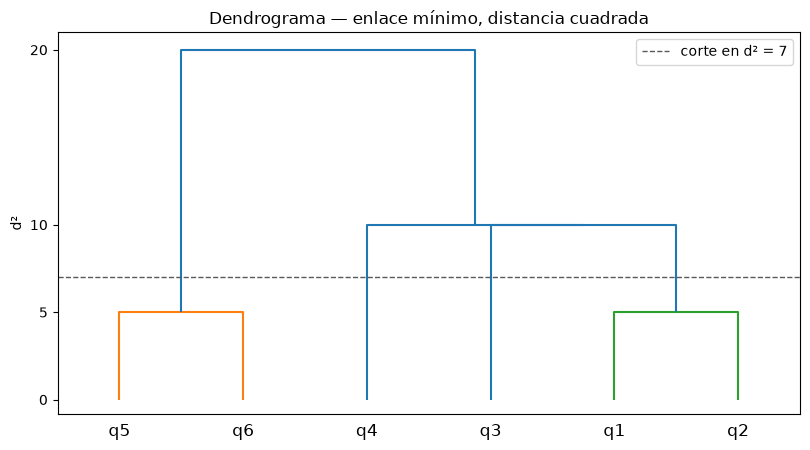

In [4]:
iniciar(FILA_B, NOMBRES_B)
_ = dendrograma(
    "Dendrograma — enlace mínimo, distancia cuadrada",
    corte=7,
    color_corte=9.99,
)

## Pregunta 4 (10 pts) — Análisis

### (a) Por qué q3 y q4 quedan con q1 y q2

El enlace mínimo usa el vecino más cercano de cada cluster. La posición “en el medio” del plano no entra en la cuenta: dos clusters están cerca cuando algún par de puntos, uno de cada lado, tiene \(d^2\) pequeña. Eso produce una cadena.

q3 se une a \(\{q_1,q_2\}\) en el paso 3:

\[
\begin{align*}
d^2(q_3,\{q_1,q_2\})&=\min(13,10)=10,\\
d^2(q_3,\{q_5,q_6\})&=\min(50,65)=50.
\end{align*}
\]

10 es menor que 50, así que q3 entra al grupo de la izquierda.

Con q3 ya dentro, q4 también queda más cerca de ese grupo que de \(\{q_5,q_6\}\):

\[
\begin{align*}
d^2(q_4,\{q_1,q_2,q_3\})&=\min(37,20,10)=10,\\
d^2(q_4,\{q_5,q_6\})&=\min(20,37)=20.
\end{align*}
\]

El 10 lo aporta q3: \(d^2(q_4,q_3)=10\). El vecino más cercano de q4 en el otro bloque es q5, con \(d^2(q_4,q_5)=20\). Por eso el paso 4 funde q4 con \(\{q_1,q_2,q_3\}\) y la última fusión, entre \(\{q_1,q_2,q_3,q_4\}\) y \(\{q_5,q_6\}\), queda para \(d^2=20\).

La cadena es q2 — q3 — q4, con dos saltos de \(d^2=10\). El enlace mínimo sigue esa cadena.

### (b) Corte para obtener exactamente 4 clusters

Cada fusión reduce en uno la cantidad de clusters:

| Después de | Altura | Clusters que quedan |
|---|---:|---|
| el inicio | — | 6 singletons |
| el paso 1 | 5 | {q1, q2}, q3, q4, q5, q6 |
| el paso 2 | 5 | {q1, q2}, q3, q4, {q5, q6} |
| el paso 3 | 10 | {q1, q2, q3}, q4, {q5, q6} |
| el paso 4 | 10 | {q1, q2, q3, q4}, {q5, q6} |
| el paso 5 | 20 | un solo cluster |

Un corte a altura \(h\) conserva las fusiones con \(d^2\le h\) y separa las de \(d^2>h\).

- En \(5\le h<10\) ya ocurrieron las dos fusiones de altura 5, y todavía no ocurren las de altura 10. Quedan **4 clusters**.
- En \(h=10\) entran las dos fusiones de altura 10 y quedan 2 clusters. No hay una altura que deje exactamente 3 clusters, porque esas dos fusiones valen lo mismo.

**Respuesta:** se corta en cualquier \(d^2\) con \(5\le d^2<10\). Por ejemplo, \(d^2=7\). Los cuatro clusters son

\[
\{q_1,q_2\},\quad \{q_3\},\quad \{q_4\},\quad \{q_5,q_6\}.
\]

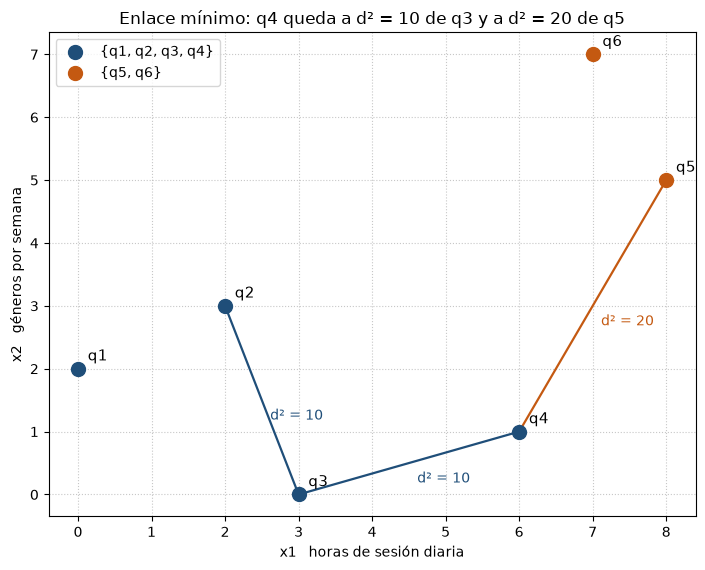

corte d² = 5     ->  4 clusters: [['q1', 'q2'], ['q3'], ['q4'], ['q5', 'q6']]
corte d² = 7     ->  4 clusters: [['q1', 'q2'], ['q3'], ['q4'], ['q5', 'q6']]
corte d² = 9.9   ->  4 clusters: [['q1', 'q2'], ['q3'], ['q4'], ['q5', 'q6']]
corte d² = 10    ->  2 clusters: [['q1', 'q2', 'q3', 'q4'], ['q5', 'q6']]
corte d² = 20    ->  1 clusters: [['q1', 'q2', 'q3', 'q4', 'q5', 'q6']]


In [5]:
iniciar(FILA_B, NOMBRES_B)
figura_encadenamiento()

for t in (5, 7, 9.9, 10, 20):
    grupos = clusters_al_corte(t)
    print(f"corte d² = {t:<4}  ->  {len(grupos)} clusters: {grupos}")

## Resumen para copiar en la hoja

**Pregunta 1.** Triángulo superior: q1–q2 = 5, q1–q3 = 13, q1–q4 = 37, q1–q5 = 73, q1–q6 = 74, q2–q3 = 10, q2–q4 = 20, q2–q5 = 40, q2–q6 = 41, q3–q4 = 10, q3–q5 = 50, q3–q6 = 65, q4–q5 = 20, q4–q6 = 37, q5–q6 = 5.

**Pregunta 2.** Cinco fusiones: (q1, q2, 5), (q5, q6, 5), ({q1, q2}, q3, 10), ({q1, q2, q3}, q4, 10), ({q1, q2, q3, q4}, {q5, q6}, 20). En cada paso la matriz nueva sale de tomar el mínimo de las dos filas que se fusionan.

**Pregunta 3.** Dendrograma con barras en 5, 10 y 20. q1–q2 y q5–q6 en 5; q1, q2, q3 y q4 unidos en 10; los dos bloques unidos en 20.

**Pregunta 4.** (a) q3 entra a la izquierda porque 10 < 50, y q4 lo sigue porque, ya con q3 dentro, 10 < 20. (b) Corte en \(5\le d^2<10\); clusters \(\{q_1,q_2\}\), \(\{q_3\}\), \(\{q_4\}\) y \(\{q_5,q_6\}\).

---

## Anexo — Ejercicios del taller

El taller deja dos conjuntos para repetir el mismo algoritmo. Las celdas de abajo imprimen la matriz inicial, cada fusión, la matriz actualizada y el dendrograma.

### Ejercicio 1

| Punto | x1 | x2 |
|------:|---:|---:|
| r1 | 0 | 0 |
| r2 | 2 | 0 |
| r3 | 6 | 1 |
| r4 | 7 | 3 |
| r5 | 4 | 5 |

Fusiones: r1 con r2 a 4; r3 con r4 a 5; {r3, r4} con r5 a 13; {r1, r2} con {r3, r4, r5} a 17.

### Ejercicio 2

| Punto | x1 | x2 |
|------:|---:|---:|
| s1 | 1 | 1 |
| s2 | 2 | 3 |
| s3 | 3 | 1 |
| s4 | 7 | 5 |
| s5 | 8 | 4 |
| s6 | 5 | 7 |

Fusiones: s4 con s5 a 2; s1 con s3 a 4; {s1, s3} con s2 a 5; {s4, s5} con s6 a 8; {s1, s2, s3} con {s4, s5, s6} a 25.

EJERCICIO 1 DEL TALLER

d²(r1, r2) = (0 - 2)² + (0 - 0)² = 4 + 0 = 4
d²(r1, r3) = (0 - 6)² + (0 - 1)² = 36 + 1 = 37
d²(r1, r4) = (0 - 7)² + (0 - 3)² = 49 + 9 = 58
d²(r1, r5) = (0 - 4)² + (0 - 5)² = 16 + 25 = 41
d²(r2, r3) = (2 - 6)² + (0 - 1)² = 16 + 1 = 17
d²(r2, r4) = (2 - 7)² + (0 - 3)² = 25 + 9 = 34
d²(r2, r5) = (2 - 4)² + (0 - 5)² = 4 + 25 = 29
d²(r3, r4) = (6 - 7)² + (1 - 3)² = 1 + 4 = 5
d²(r3, r5) = (6 - 4)² + (1 - 5)² = 4 + 16 = 20
d²(r4, r5) = (7 - 4)² + (3 - 5)² = 9 + 4 = 13

Matriz inicial
      r1  r2  r3  r4  r5
  r1   —   4  37  58  41
  r2       —  17  34  29
  r3           —   5  20
  r4               —  13
  r5                   —

========== Paso 1 ==========
Mínimo d² = 4
Se fusionan r1 y r2 a altura d² = 4.
  d²(nuevo, r3) = min(37, 17) = 17
  d²(nuevo, r4) = min(58, 34) = 34
  d²(nuevo, r5) = min(41, 29) = 29
Matriz actualizada:
            {r1, r2}        r3        r4        r5
  {r1, r2}         —        17        34        29
        r3                   —      

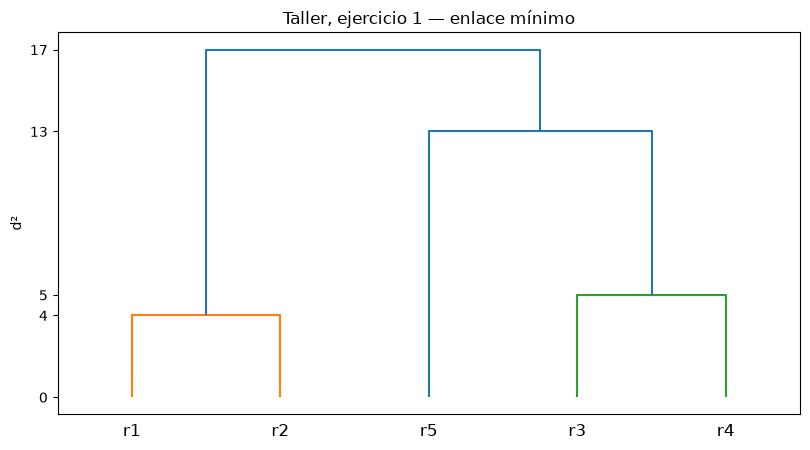

Ejercicio 1: alturas verificadas con scipy.


EJERCICIO 2 DEL TALLER

d²(s1, s2) = (1 - 2)² + (1 - 3)² = 1 + 4 = 5
d²(s1, s3) = (1 - 3)² + (1 - 1)² = 4 + 0 = 4
d²(s1, s4) = (1 - 7)² + (1 - 5)² = 36 + 16 = 52
d²(s1, s5) = (1 - 8)² + (1 - 4)² = 49 + 9 = 58
d²(s1, s6) = (1 - 5)² + (1 - 7)² = 16 + 36 = 52
d²(s2, s3) = (2 - 3)² + (3 - 1)² = 1 + 4 = 5
d²(s2, s4) = (2 - 7)² + (3 - 5)² = 25 + 4 = 29
d²(s2, s5) = (2 - 8)² + (3 - 4)² = 36 + 1 = 37
d²(s2, s6) = (2 - 5)² + (3 - 7)² = 9 + 16 = 25
d²(s3, s4) = (3 - 7)² + (1 - 5)² = 16 + 16 = 32
d²(s3, s5) = (3 - 8)² + (1 - 4)² = 25 + 9 = 34
d²(s3, s6) = (3 - 5)² + (1 - 7)² = 4 + 36 = 40
d²(s4, s5) = (7 - 8)² + (5 - 4)² = 1 + 1 = 2
d²(s4, s6) = (7 - 5)² + (5 - 7)² = 4 + 4 = 8
d²(s5, s6) = (8 - 5)² + (4 - 7)² = 9 + 9 = 18

Matriz inicial
      s1  s2  s3  s4  s5  s6
  s1   —   5   4  52  58  52
  s2       —   5  29  37  25
  s3           —  32  34  40
  s4               —   2   8
  s5                   —  18
  s6                       —

========== Pa

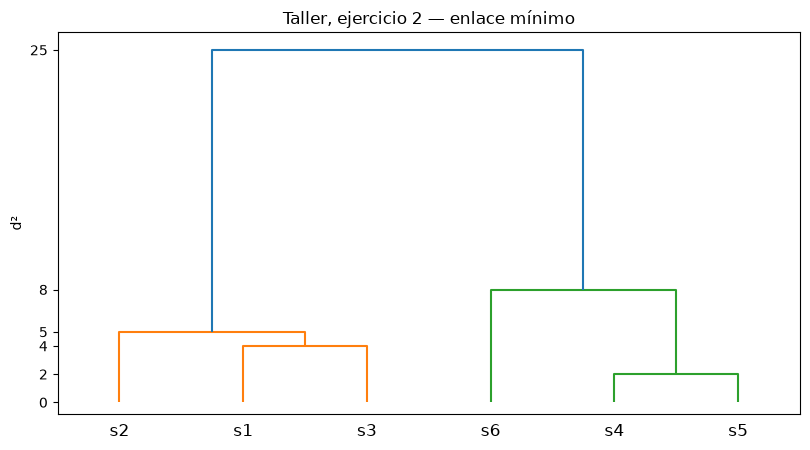

Ejercicio 2: alturas verificadas con scipy.


In [6]:
print("EJERCICIO 1 DEL TALLER\n")
iniciar(TALLER_1, NOMBRES_1)
detalle_pares()
print()
historial_1 = correr()
Z1 = dendrograma("Taller, ejercicio 1 — enlace mínimo")
assert [dist for _, dist in historial_1] == [int(h) for h in Z1[:, 2]]
print("Ejercicio 1: alturas verificadas con scipy.")

print("\n\nEJERCICIO 2 DEL TALLER\n")
iniciar(TALLER_2, NOMBRES_2)
detalle_pares()
print()
historial_2 = correr()
Z2 = dendrograma("Taller, ejercicio 2 — enlace mínimo")
assert [dist for _, dist in historial_2] == [int(h) for h in Z2[:, 2]]
print("Ejercicio 2: alturas verificadas con scipy.")